<a href="https://colab.research.google.com/github/shriharimeharwade9-design/ml-mini-project/blob/main/Fake_Job_Posting_Detector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fake Job Posting Risk Checker
**Applied Machine Learning Mini-Project (Google Colab)**

This notebook follows the chapters of the BTech ML Mini-Project template:
1. Data loading and EDA (Chapter 3.1)
2. Leakage-safe split and preprocessing (Chapter 3.2)
3. Red-flag feature engineering (Chapter 3.3)
4. Baseline and candidate models (Chapter 4.2)
5. Hyperparameter tuning (Chapter 4.3)
6. Evaluation, confusion matrix, and error analysis (Chapter 5)
7. Saving the model for the Streamlit app (Chapter 5.3)

**Before you start:** download the dataset "Real / Fake Job Posting Prediction" from Kaggle (a CSV file named `fake_job_postings.csv`). You will upload it when the notebook asks.

## Step 0: Imports

In [1]:
import re, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, accuracy_score)
from xgboost import XGBClassifier

sns.set_theme(style='whitegrid')

## Step 1: Load the dataset

Colab will show an upload button. Choose your `fake_job_postings.csv` file.

In [2]:
try:
    from google.colab import files
    uploaded = files.upload()
    csv_name = next(iter(uploaded))
except ImportError:
    csv_name = 'fake_job_postings.csv'   # used only when running outside Colab

df = pd.read_csv(csv_name)
print("Shape:", df.shape)
df.head(3)

Saving fake_job_postings.csv to fake_job_postings (2).csv
Shape: (17880, 18)


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0


## Step 2: Exploratory Data Analysis (Chapter 3.1)

We check the class balance first. Because only a small share of postings are fraudulent, accuracy alone can be misleading. This is why the report uses precision, recall, F1, and PR-AUC.

Total postings: 17880
Fraudulent share: 4.84%

Top missing-value columns (%):
salary_range           84.0
department             64.6
required_education     45.3
benefits               40.3
required_experience    39.4
function               36.1
industry               27.4
employment_type        19.4
dtype: float64


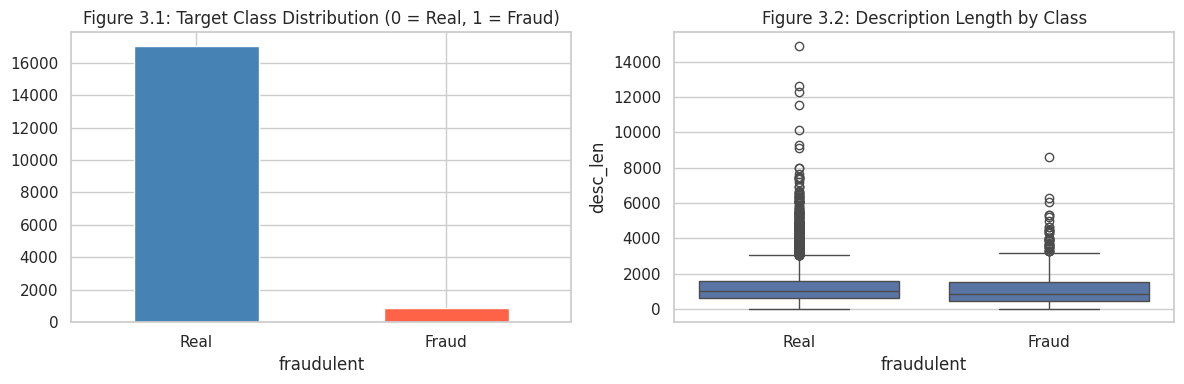

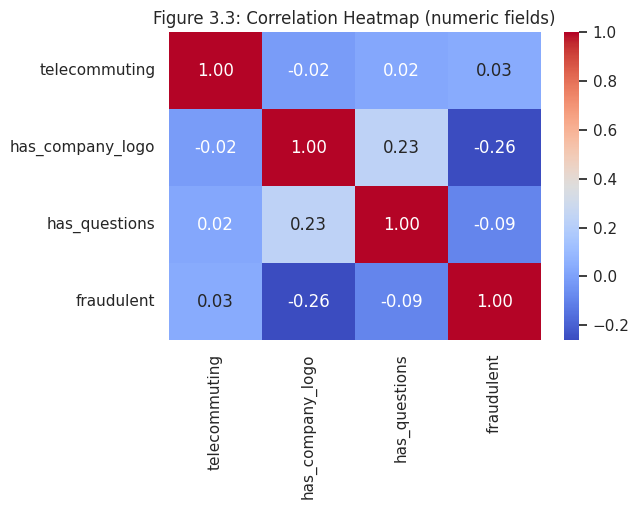

In [3]:
print("Total postings:", len(df))
print("Fraudulent share: {:.2f}%".format(df['fraudulent'].mean() * 100))
print("\nTop missing-value columns (%):")
print((df.isna().mean() * 100).round(1).sort_values(ascending=False).head(8))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df['fraudulent'].value_counts().sort_index().plot.bar(ax=ax[0], color=['steelblue', 'tomato'])
ax[0].set_title('Figure 3.1: Target Class Distribution (0 = Real, 1 = Fraud)')
ax[0].set_xticklabels(['Real', 'Fraud'], rotation=0)

desc_len = df.assign(desc_len=df['description'].fillna('').str.len())
sns.boxplot(data=desc_len, x='fraudulent', y='desc_len', ax=ax[1])
ax[1].set_title('Figure 3.2: Description Length by Class')
ax[1].set_xticklabels(['Real', 'Fraud'])
plt.tight_layout()
plt.show()

numeric = df.select_dtypes('number').drop(columns='job_id', errors='ignore')
plt.figure(figsize=(6, 4))
sns.heatmap(numeric.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Figure 3.3: Correlation Heatmap (numeric fields)')
plt.show()

## Step 3: Red-flag feature engineering (Chapter 3.3)

These features encode what a job-seeker would notice: payment requests, chat-only contact, "easy money" wording, urgency pressure, and requests for personal or bank details. The features are counted with regular expressions, so they are easy to explain in the report.

The features are built from each row on its own (no statistics are learned from the data), so they are safe to compute before the split. Anything that *learns* from data, such as the TF-IDF vocabulary, scalers, or imputers, is fitted only inside the training pipeline.

In [4]:
TEXT_COLS = ['title', 'location', 'department', 'company_profile', 'description',
             'requirements', 'benefits', 'industry', 'function']
CAT_COLS = ['employment_type', 'required_experience', 'required_education']
BIN_COLS = ['telecommuting', 'has_company_logo', 'has_questions']

RED_FLAGS = {
    'flag_payment':       r'registration fee|training fee|security deposit|kit fee|fee of|pay (?:a|the|us|for)\b',
    'flag_chat_contact':  r'whatsapp|telegram|wechat|gmail|yahoo|hotmail|text us',
    'flag_easy_money':    r'\bearn\b|per day|per week|weekly income|daily income|lakh per month|unlimited income|no experience (?:needed|required)',
    'flag_urgency':       r'urgent|immediate joining|hurry|limited (?:seats|slots)|apply now|act fast',
    'flag_personal_info': r'bank (?:account|details)|aadhaar|pan card|passport|\bssn\b|id proof|social security',
}

def build_features(raw):
    d = raw.copy()
    # Missing-field signals (computed before filling blanks)
    d['has_salary'] = d['salary_range'].notna().astype(float)
    d['no_company_profile'] = d['company_profile'].isna().astype(float)

    for c in TEXT_COLS + CAT_COLS:
        d[c] = d[c].fillna('').astype(str)
    for c in BIN_COLS:
        d[c] = d[c].fillna(0).astype(float)

    d['text'] = d[TEXT_COLS].agg(' '.join, axis=1)

    for name, pattern in RED_FLAGS.items():
        d[name] = d['text'].str.count(pattern, flags=re.IGNORECASE)

    d['desc_len'] = np.log1p(d['description'].str.len())
    d['total_flags'] = d[list(RED_FLAGS)].sum(axis=1)
    return d

data = build_features(df)
NUM_COLS = BIN_COLS + ['has_salary', 'no_company_profile', 'desc_len', 'total_flags'] + list(RED_FLAGS)

print("Average red-flag hits per posting:")
print(data.groupby('fraudulent')[list(RED_FLAGS)].mean().round(3))

Average red-flag hits per posting:
            flag_payment  flag_chat_contact  flag_easy_money  flag_urgency  \
fraudulent                                                                   
0                  0.013              0.020            0.094         0.091   
1                  0.007              0.003            0.405         0.095   

            flag_personal_info  
fraudulent                      
0                        0.050  
1                        0.007  


## Step 4: Train/test split before any fitting (Chapter 3.2)

We split first and use stratification so both sets keep the same fraud rate. The test set is locked away and used only at the end.

In [5]:
X = data[['text'] + NUM_COLS + CAT_COLS]
y = data['fraudulent'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, "fraud rate:", round(y_train.mean(), 3))
print("Test: ", X_test.shape, "fraud rate:", round(y_test.mean(), 3))

Train: (14304, 16) fraud rate: 0.048
Test:  (3576, 16) fraud rate: 0.048


## Step 5: Preprocessing pipeline (Chapter 3.2 and 4.1)

One `ColumnTransformer` handles three kinds of input: TF-IDF for text, scaling for numbers, and one-hot encoding for categories. It is placed inside a `Pipeline`, so every imputer, scaler, and vectorizer is fitted only on training folds during cross-validation.

In [6]:
def make_preprocessor():
    return ColumnTransformer([
        ('text', TfidfVectorizer(max_features=10000, ngram_range=(1, 2),
                                 min_df=2, stop_words='english'), 'text'),
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                          ('sc', StandardScaler())]), NUM_COLS),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh', OneHotEncoder(handle_unknown='ignore'))]), CAT_COLS),
    ])

pos = y_train.sum()
neg = (y_train == 0).sum()

models = {
    'Baseline: Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                            random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=200, learning_rate=0.1,
                             scale_pos_weight=float(neg / pos),
                             eval_metric='logloss', random_state=42),
    'Linear SVM': LinearSVC(class_weight='balanced', max_iter=5000),
}

# clone() gives every pipeline its own preprocessor so nothing is shared
pipes = {name: Pipeline([('pre', make_preprocessor()), ('clf', m)])
         for name, m in models.items()}

## Step 6: Model selection with cross-validation (Chapter 4.2)

We pick the best model using 5-fold cross-validation on the **training set only**, so the test set is not used to make choices. The metric is F1, which balances precision and recall for the fraud class.

In [7]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = []
for name, pipe in pipes.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=skf, scoring='f1', n_jobs=-1)
    cv_rows.append({'Model': name, 'CV F1 (mean)': scores.mean(), 'CV F1 (std)': scores.std()})

cv_table = pd.DataFrame(cv_rows).sort_values('CV F1 (mean)', ascending=False)
cv_table.round(3)

,Model,CV F1 (mean),CV F1 (std)
3,Linear SVM,0.820,0.022
2,XGBoost,0.797,0.031
1,Random Forest,0.718,0.035
0,Baseline: Logistic Regression,0.664,0.016


## Step 7: Hyperparameter tuning (Chapter 4.3)

We tune the top-ranked model with RandomizedSearchCV. Random search is faster than grid search and works well for this size of search space.

In [8]:
best_name = cv_table.iloc[0]['Model']
print("Best model by CV F1:", best_name)

param_grids = {
    'Baseline: Logistic Regression': {'clf__C': [0.1, 0.3, 1, 3, 10]},
    'Random Forest': {'clf__n_estimators': [200, 400],
                      'clf__max_depth': [None, 20, 40],
                      'clf__min_samples_leaf': [1, 2, 4]},
    'XGBoost': {'clf__n_estimators': [200, 400],
                'clf__max_depth': [3, 5, 7],
                'clf__learning_rate': [0.03, 0.1, 0.2],
                'clf__subsample': [0.8, 1.0]},
    'Linear SVM': {'clf__C': [0.1, 0.3, 0.5, 1, 2]},
}

search = RandomizedSearchCV(pipes[best_name], param_grids[best_name], n_iter=8,
                            cv=skf, scoring='f1', random_state=42, n_jobs=-1)
search.fit(X_train, y_train)

print("Best CV F1:", round(search.best_score_, 3))
print("Best parameters:", search.best_params_)
tuned = search.best_estimator_

Best model by CV F1: Linear SVM
Best CV F1: 0.82
Best parameters: {'clf__C': 1}


## Step 8: Final evaluation on the held-out test set (Chapter 5.1)

Now every model is trained on the full training set and scored once on the test set. Accuracy is shown for completeness, but the report focuses on Precision, Recall, F1, ROC-AUC, and PR-AUC.

In [9]:
def evaluate(name, model, X_, y_):
    pred = model.predict(X_)
    if hasattr(model, 'predict_proba'):
        score = model.predict_proba(X_)[:, 1]
    else:
        score = model.decision_function(X_)   # LinearSVC has no predict_proba
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_, pred),
        'Precision': precision_score(y_, pred, zero_division=0),
        'Recall': recall_score(y_, pred, zero_division=0),
        'F1': f1_score(y_, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_, score),
        'PR-AUC': average_precision_score(y_, score),
    }

results = []
for name, pipe in pipes.items():
    pipe.fit(X_train, y_train)
    results.append(evaluate(name, pipe, X_test, y_test))
results.append(evaluate('Tuned: ' + best_name, tuned, X_test, y_test))

results_table = pd.DataFrame(results).round(3)
results_table

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Baseline: Logistic Regression,0.964,0.583,0.890,0.705,0.990,0.892
1,Random Forest,0.980,1.000,0.590,0.742,0.993,0.919
2,XGBoost,0.985,0.841,0.855,0.848,0.989,0.927
3,Linear SVM,0.985,0.834,0.873,0.853,0.992,0.936
4,Tuned: Linear SVM,0.985,0.834,0.873,0.853,0.992,0.936


## Step 9: Confusion matrix and classification report (Chapter 5.2)

              precision    recall  f1-score   support

        Real       0.99      0.99      0.99      3403
       Fraud       0.83      0.87      0.85       173

    accuracy                           0.99      3576
   macro avg       0.91      0.93      0.92      3576
weighted avg       0.99      0.99      0.99      3576



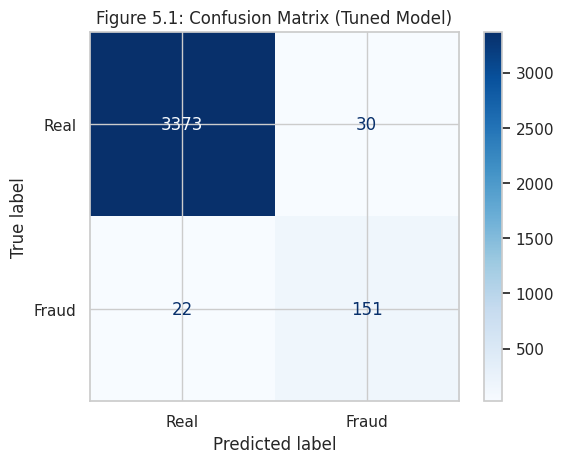

In [10]:
pred_tuned = tuned.predict(X_test)
print(classification_report(y_test, pred_tuned, target_names=['Real', 'Fraud']))

ConfusionMatrixDisplay.from_predictions(y_test, pred_tuned,
                                        display_labels=['Real', 'Fraud'], cmap='Blues')
plt.title('Figure 5.1: Confusion Matrix (Tuned Model)')
plt.show()

## Step 10: Error analysis (Chapter 5.2)

**False positives** are real jobs flagged as fraud. **False negatives** are scams the model missed. Looking at both helps you explain failure cases in the report.

In [11]:
err = X_test.assign(actual=y_test.values, predicted=pred_tuned,
                    title=data.loc[X_test.index, 'title'])

print("Examples of FALSE POSITIVES (real jobs flagged as fraud):")
display(err[(err.predicted == 1) & (err.actual == 0)][['title', 'total_flags']].head(5))

print("Examples of FALSE NEGATIVES (scams that were missed):")
display(err[(err.predicted == 0) & (err.actual == 1)][['title', 'total_flags']].head(5))

Examples of FALSE POSITIVES (real jobs flagged as fraud):


,title,total_flags
16995,EXCELLENT ER RN Opportunity Available Now,1
882,Service Champion Full-time and Part-time,0
7225,Customer support for e-shop with decorative ob...,0
4478,Controls Engineer- Programming & Debug of PLC-...,0
6248,Sales Representative,0


Examples of FALSE NEGATIVES (scams that were missed):


,title,total_flags
17648,Vemma Brand Partner,0
17549,Sales manager,0
7177,Fraud Detection Analyst,0
17598,Real Estate & Insurance Professionals,0
10407,Hotel Workers Needed,0


## Step 11: Which words matter? (feature importance, Chapter 5.2)

The Logistic Regression baseline is easy to read: each word has a coefficient. Positive values push a posting toward *fraud*, and negative values push it toward *real*.

In [12]:
lr_pipe = pipes['Baseline: Logistic Regression']
feature_names = lr_pipe.named_steps['pre'].get_feature_names_out()
coefs = pd.Series(lr_pipe.named_steps['clf'].coef_[0], index=feature_names)

print("Strongest signals of FRAUD:")
print(coefs.sort_values(ascending=False).head(15).round(3))
print("\nStrongest signals of REAL:")
print(coefs.sort_values().head(10).round(3))

Strongest signals of FRAUD:
text__aptitude staffing     4.024
text__administrative        3.802
text__money                 3.767
text__link                  3.605
text__oil                   3.302
text__supplier              3.285
text__aptitude              3.113
text__data entry            2.990
text__000                   2.971
text__financing             2.934
text__hotel                 2.882
text__engineering           2.796
text__signing bonus         2.736
text__staffing solutions    2.405
text__hospital              2.382
dtype: float64

Strongest signals of REAL:
text__team        -2.459
text__companies   -2.177
text__english     -2.088
text__software    -1.998
text__growing     -1.844
text__web         -1.781
text__search      -1.740
text__php         -1.729
text__50          -1.689
text__fun         -1.661
dtype: float64


## Step 12: Save the model for the Streamlit app (Chapter 5.3)

The whole pipeline is saved as one file, so the app can take raw text and fields and return a risk score with no extra steps.

In [13]:
joblib.dump(tuned, 'job_scam_model.joblib')
print("Saved job_scam_model.joblib")

sample = X_test.iloc[[0]]
if hasattr(tuned, 'predict_proba'):
    print("Predicted fraud probability:", round(tuned.predict_proba(sample)[0, 1], 3))
else:
    print("Model score (decision value):", round(tuned.decision_function(sample)[0], 3))

try:
    from google.colab import files
    files.download('job_scam_model.joblib')
except ImportError:
    pass

Saved job_scam_model.joblib
Model score (decision value): 0.136


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>